# Hospital Readmission Analytics — Python Analysis

Companion to the SQL project. The SQL layer builds the database, reports and the rule-based risk score. This notebook uses Python (pandas, scikit-learn) on the same dataset to:

1. Reproduce the key SQL findings (readmission rate, prior stays, the 4.5% Pareto result).
2. Build a risk model and **test it on patients it has never seen** (the SQL score was checked on the same data used to design it).
3. Rank the factors that go with readmission.
4. Group patients into segments and compare their readmission rates.

**Data:** `diabetic_data.csv` from the UCI "Diabetes 130-US Hospitals (1999–2008)" dataset. Put it at `data/diabetic_data.csv`.

All findings are descriptive (associations), not proof of cause.

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, silhouette_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

DATA_PATH = "/kaggle/input/datasets/dharshinidhanam/diabetic-data-csv/diabetic_data.csv"   # change if your CSV is elsewhere
FIG_DIR = "docs"                       # charts are saved here
RANDOM_STATE = 42
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, AMBER, GREY = "#0fb5a0", "#f5a800", "#8a94a6"

## 1. Load and clean

Same rules as the SQL project: `?` means missing, and encounters that ended in death or hospice are excluded because those patients cannot be readmitted (CMS convention).

In [4]:
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["?"])   # keep the text "None" (HbA1c not tested) as a value
print("Raw encounters:", len(raw))

df = raw.drop_duplicates("encounter_id").copy()
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

# 11 = expired, 13/14 = hospice, 19/20/21 = expired variants
EXCLUDE_DISCHARGE = [11, 13, 14, 19, 20, 21]
elig = df[~df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)].copy().reset_index(drop=True)

print("Eligible encounters:", len(elig))
print("Unique patients:", elig["patient_nbr"].nunique())
print(f"30-day readmission rate: {elig['readmitted_30d'].mean():.2%}  ({elig['readmitted_30d'].sum():,} readmissions)")
print(f"HbA1c not tested: {(elig['A1Cresult'] == 'None').mean():.0%} of encounters")

Raw encounters: 101766
Eligible encounters: 99343
Unique patients: 69990
30-day readmission rate: 11.39%  (11,314 readmissions)
HbA1c not tested: 83% of encounters


**Check against the SQL project:** it reports 99,340 eligible encounters and an 11.39% readmission rate. A difference of a few rows is expected because the SQL pipeline also rejects a few invalid rows.

## 2. Reproduce the key findings

,encounters,readmit_rate
prior_stays_band,,
0,"66,245",8.6%
1-2,"26,284",14.6%
3-4,"4,845",22.0%
5+,"1,969",37.1%


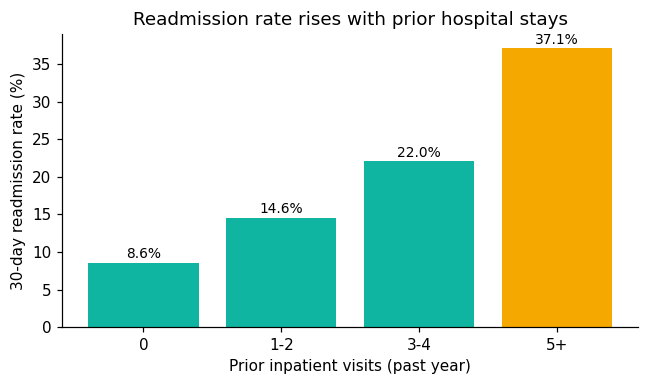

In [5]:
elig["prior_stays_band"] = pd.cut(elig["number_inpatient"], bins=[-1, 0, 2, 4, 1000],
                                  labels=["0", "1-2", "3-4", "5+"])
by_prior = (elig.groupby("prior_stays_band", observed=True)["readmitted_30d"]
                .agg(encounters="size", readmit_rate="mean"))
display(by_prior.style.format({"encounters": "{:,}", "readmit_rate": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(6, 3.6))
colors = [TEAL, TEAL, TEAL, AMBER]
ax.bar(by_prior.index.astype(str), by_prior["readmit_rate"] * 100, color=colors)
for i, v in enumerate(by_prior["readmit_rate"] * 100):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("Prior inpatient visits (past year)")
ax.set_ylabel("30-day readmission rate (%)")
ax.set_title("Readmission rate rises with prior hospital stays")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_prior_stays.png"); plt.show()

,encounters,readmit_rate
discharge,,
Long-term care hospital,412,7.3%
Home,"60,234",9.3%
Home with home health,"12,902",12.7%
Intermediate care,815,12.8%
Skilled nursing facility,"13,954",14.7%
Short-term hospital,"2,128",16.1%
Other inpatient care,"1,184",20.9%
Rehab facility,"1,993",27.7%


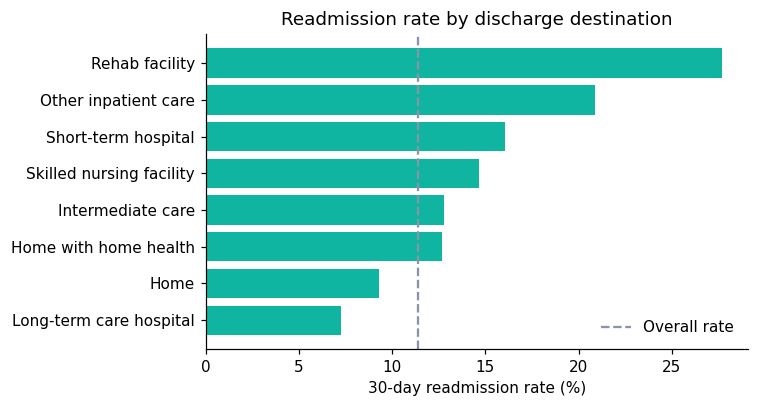

In [6]:
DISCHARGE_NAMES = {1: "Home", 2: "Short-term hospital", 3: "Skilled nursing facility",
                   4: "Intermediate care", 5: "Other inpatient care", 6: "Home with home health",
                   22: "Rehab facility", 23: "Long-term care hospital"}
d = elig[elig["discharge_disposition_id"].isin(DISCHARGE_NAMES)].copy()
d["discharge"] = d["discharge_disposition_id"].map(DISCHARGE_NAMES)
by_dis = d.groupby("discharge")["readmitted_30d"].agg(encounters="size", readmit_rate="mean")
by_dis = by_dis[by_dis["encounters"] >= 300].sort_values("readmit_rate")
display(by_dis.style.format({"encounters": "{:,}", "readmit_rate": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(by_dis.index, by_dis["readmit_rate"] * 100, color=TEAL)
ax.axvline(elig["readmitted_30d"].mean() * 100, color=GREY, ls="--", label="Overall rate")
ax.set_xlabel("30-day readmission rate (%)"); ax.set_title("Readmission rate by discharge destination")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_discharge.png"); plt.show()

3,148 of 69,990 patients (4.5%) account for 50% of readmissions


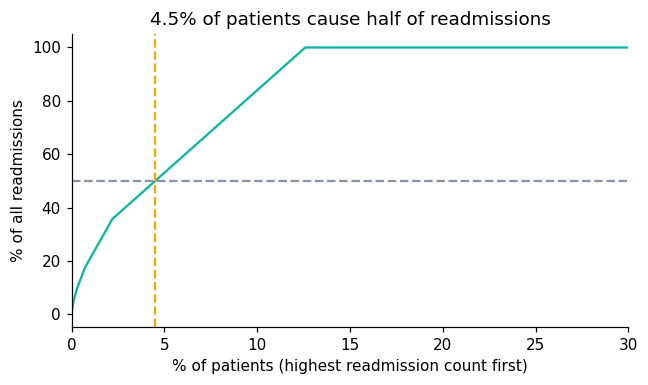

In [7]:
# Pareto: what share of patients account for half of all readmissions?
per_patient = (elig.groupby("patient_nbr")["readmitted_30d"].sum()
                   .sort_values(ascending=False))
cum_share = per_patient.cumsum() / per_patient.sum()
n_half = int((cum_share < 0.5).sum() + 1)
pct_patients = n_half / len(per_patient)
print(f"{n_half:,} of {len(per_patient):,} patients ({pct_patients:.1%}) account for 50% of readmissions")

x = np.arange(1, len(per_patient) + 1) / len(per_patient) * 100
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(x, cum_share.values * 100, color=TEAL)
ax.axhline(50, color=GREY, ls="--"); ax.axvline(pct_patients * 100, color=AMBER, ls="--")
ax.set_xlim(0, 30)
ax.set_xlabel("% of patients (highest readmission count first)")
ax.set_ylabel("% of all readmissions")
ax.set_title(f"{pct_patients:.1%} of patients cause half of readmissions")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_pareto.png"); plt.show()

## 3. Build a risk model and test it on unseen patients

**Why this matters:** the SQL risk score was checked on the same data used to design it. Here the model is trained on 80% of patients and judged only on the other 20%.

**Why split by patient:** the same patient appears in many encounters. If one patient's encounters landed in both train and test, the model could memorize them and look better than it really is. `GroupShuffleSplit` keeps each patient entirely in one side.

In [8]:
def icd_group(code):
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):
        return "Other"
    try:
        v = float(c)
    except ValueError:
        return "Other"
    i = int(v)
    if 390 <= v < 460 or i == 785: return "Circulatory"
    if 460 <= v < 520 or i == 786: return "Respiratory"
    if 520 <= v < 580 or i == 787: return "Digestive"
    if i == 250:                   return "Diabetes"
    if 800 <= v < 1000:            return "Injury"
    if 710 <= v < 740:             return "Musculoskeletal"
    if 580 <= v < 630 or i == 788: return "Genitourinary"
    if 140 <= v < 240:             return "Neoplasms"
    return "Other"

elig["age_mid"] = elig["age"].str.extract(r"\[(\d+)")[0].astype(float) + 5
elig["diag1_group"] = elig["diag_1"].map(icd_group)

top_specs = elig["medical_specialty"].value_counts().head(10).index
elig["specialty_grp"] = np.where(elig["medical_specialty"].isna(), "Missing",
                         np.where(elig["medical_specialty"].isin(top_specs), elig["medical_specialty"], "Other"))

NUM = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
CAT = ["gender", "race", "admission_type_id", "admission_source_id", "discharge_disposition_id",
       "A1Cresult", "max_glu_serum", "change", "diabetesMed", "specialty_grp", "diag1_group"]

X = elig[NUM + CAT].copy()
for c in CAT:
    X[c] = X[c].astype("object").where(X[c].notna(), "Missing").astype(str)
y = elig["readmitted_30d"].reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups=elig["patient_nbr"]))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr].values, y.iloc[te].values

overlap = set(elig.loc[tr, "patient_nbr"]) & set(elig.loc[te, "patient_nbr"])
print(f"Train: {len(tr):,} encounters | Test: {len(te):,} encounters | patients in both: {len(overlap)}")
print(f"Readmission rate  train {y_tr.mean():.2%}  test {y_te.mean():.2%}")

Train: 79,541 encounters | Test: 19,802 encounters | patients in both: 0
Readmission rate  train 11.44%  test 11.19%


In [9]:
def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT),
    ])

logit = Pipeline([("pre", make_pre()),
                  ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
forest = Pipeline([("pre", make_pre()),
                   ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=30, max_features="sqrt",
                                                  class_weight="balanced_subsample", n_jobs=-1,
                                                  random_state=RANDOM_STATE))])
logit.fit(X_tr, y_tr)
forest.fit(X_tr, y_tr)

scores = {
    "Baseline: prior visits only": X_te["number_inpatient"].values.astype(float),
    "Logistic regression": logit.predict_proba(X_te)[:, 1],
    "Random forest": forest.predict_proba(X_te)[:, 1],
}

def evaluate(score, y_true, top_frac=0.10):
    k = int(len(y_true) * top_frac)
    top = np.argsort(-score, kind="stable")[:k]
    precision = y_true[top].mean()
    return {"ROC-AUC": roc_auc_score(y_true, score),
            "Avg precision": average_precision_score(y_true, score),
            "Top-10% precision": precision,
            "Top-10% recall": y_true[top].sum() / y_true.sum(),
            "Top-10% lift": precision / y_true.mean()}

### Optional: compare with the SQL rule-based score

Export the SQL score for every encounter from PostgreSQL, save it next to this notebook as `sql_risk_scores.csv`, and the next cell adds it to the comparison. Adjust the schema and function names to match your database.

```sql
\copy (SELECT encounter_id, hosp.fn_readmission_risk_score(encounter_id) AS risk_score FROM hosp.encounter) TO 'sql_risk_scores.csv' CSV HEADER
```

If the file is missing, the cell just skips this step.

In [10]:
SQL_SCORES = "sql_risk_scores.csv"
results_scores = dict(scores)
mask_all = np.ones(len(y_te), dtype=bool)

if os.path.exists(SQL_SCORES):
    s = pd.read_csv(SQL_SCORES).set_index("encounter_id")["risk_score"]
    sql_te = elig.loc[te, "encounter_id"].map(s).values.astype(float)
    ok = ~np.isnan(sql_te)
    print(f"SQL score found for {ok.sum():,} of {len(ok):,} test encounters")
    results_scores["SQL rule-based score"] = np.where(ok, sql_te, np.nanmin(sql_te))
else:
    print("sql_risk_scores.csv not found - skipping SQL score comparison")

results = pd.DataFrame({name: evaluate(sc, y_te) for name, sc in results_scores.items()}).T
display(results.style.format({"ROC-AUC": "{:.3f}", "Avg precision": "{:.3f}", "Top-10% precision": "{:.1%}",
                              "Top-10% recall": "{:.1%}", "Top-10% lift": "{:.2f}x"}))
print(f"Test-set base rate: {y_te.mean():.1%}")

sql_risk_scores.csv not found - skipping SQL score comparison


,ROC-AUC,Avg precision,Top-10% precision,Top-10% recall,Top-10% lift
Baseline: prior visits only,0.602,0.172,24.2%,21.6%,2.16x
Logistic regression,0.660,0.216,26.5%,23.7%,2.37x
Random forest,0.669,0.225,26.4%,23.6%,2.36x


Test-set base rate: 11.2%


**How to read this table**

- **ROC-AUC:** 0.5 = random guessing, 1.0 = perfect. Predicting 30-day readmission is hard, and published models on this dataset usually land around 0.60–0.70, so a modest improvement over the baseline is a normal, honest result.
- **Top-10% precision:** among the 10% of test encounters the model ranks highest, the share that were actually readmitted.
- **Top-10% lift:** that share divided by the overall rate. A lift of 2x means the top group is twice as likely to be readmitted as an average patient.

Best model on test set: Random forest


,encounters,readmit_rate
decile,,
1,"1,981",4.4%
2,"1,980",5.7%
3,"1,980",6.9%
4,"1,980",7.4%
5,"1,980",8.6%
6,"1,980",9.0%
7,"1,980",12.5%
8,"1,980",13.9%
9,"1,980",17.1%


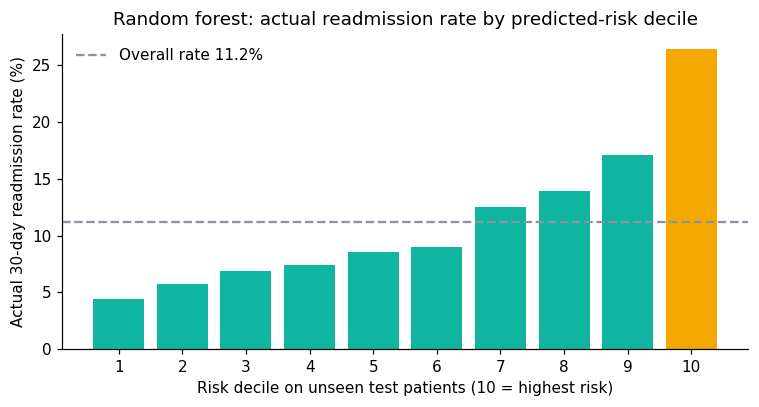

,encounters,readmit_rate,lift_vs_low
tier,,,
LOW (bottom 70%),"13,861",7.8%,1.00x
MEDIUM (next 20%),"3,960",15.5%,1.99x
HIGH (top 10%),"1,981",26.4%,3.39x


In [11]:
best_name = results["ROC-AUC"].drop("Baseline: prior visits only").idxmax()
best_score = results_scores[best_name]
print("Best model on test set:", best_name)

# Decile view: rank test encounters by risk, 10 = highest-risk tenth
rank = pd.Series(best_score).rank(method="first")
decile = pd.qcut(rank, 10, labels=False) + 1
dec = (pd.DataFrame({"decile": decile, "y": y_te}).groupby("decile")["y"]
         .agg(encounters="size", readmit_rate="mean"))
display(dec.style.format({"encounters": "{:,}", "readmit_rate": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(dec.index, dec["readmit_rate"] * 100, color=[AMBER if i == 10 else TEAL for i in dec.index])
ax.axhline(y_te.mean() * 100, color=GREY, ls="--", label=f"Overall rate {y_te.mean():.1%}")
ax.set_xticks(dec.index); ax.set_xlabel("Risk decile on unseen test patients (10 = highest risk)")
ax.set_ylabel("Actual 30-day readmission rate (%)")
ax.set_title(f"{best_name}: actual readmission rate by predicted-risk decile")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_risk_deciles.png"); plt.show()

# Tier view (adjust the cut-offs to your call capacity)
tier = pd.cut(decile, bins=[0, 7, 9, 10], labels=["LOW (bottom 70%)", "MEDIUM (next 20%)", "HIGH (top 10%)"])
tiers = (pd.DataFrame({"tier": tier, "y": y_te}).groupby("tier", observed=True)["y"]
           .agg(encounters="size", readmit_rate="mean"))
tiers["lift_vs_low"] = tiers["readmit_rate"] / tiers.loc["LOW (bottom 70%)", "readmit_rate"]
display(tiers.style.format({"encounters": "{:,}", "readmit_rate": "{:.1%}", "lift_vs_low": "{:.2f}x"}))

## 4. What goes with readmission? (feature importance)

Permutation importance shuffles one feature at a time on the unseen test data and measures how much the model's ROC-AUC drops. A bigger drop means the model relies on that feature more.

These are **associations**, not causes.

,AUC drop when shuffled
number_inpatient,0.0611
discharge_disposition_id,0.0456
diag1_group,0.0061
time_in_hospital,0.0047
age_mid,0.0038
number_emergency,0.0035
specialty_grp,0.0031
gender,0.0021
num_lab_procedures,0.0020
number_diagnoses,0.0019


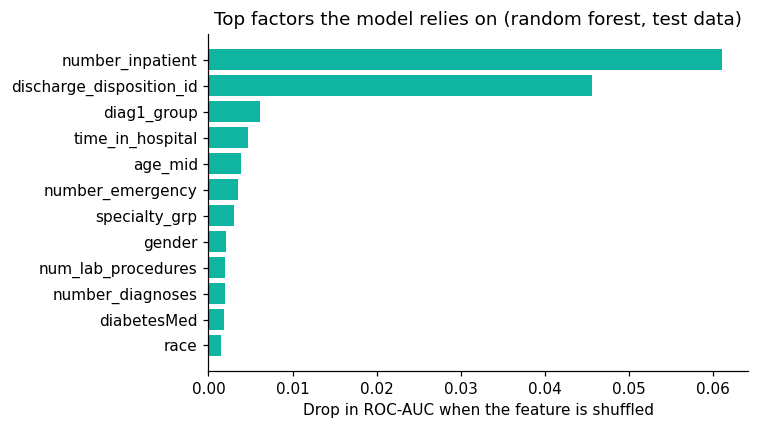

In [12]:
sample = np.random.RandomState(RANDOM_STATE).choice(len(X_te), size=min(6000, len(X_te)), replace=False)
pi = permutation_importance(forest, X_te.iloc[sample], y_te[sample], scoring="roc_auc",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False).head(12))
display(imp.to_frame("AUC drop when shuffled").style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color=TEAL)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("Top factors the model relies on (random forest, test data)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_feature_importance.png"); plt.show()

## 5. Patient segments

K-means groups encounters with similar profiles (age, length of stay, medications, prior visits). The groups are found **without** looking at readmission. Afterwards we check which groups readmit more.

In [13]:
SEG = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_medications",
       "number_diagnoses", "number_outpatient", "number_emergency", "number_inpatient"]
seg_df = elig[SEG].copy()
seg_df = seg_df.fillna(seg_df.median())
seg_df = seg_df.clip(upper=seg_df.quantile(0.99), axis=1)       # limit extreme outliers
Z = StandardScaler().fit_transform(seg_df)

# Pick the number of segments with the silhouette score on a sample
rs = np.random.RandomState(RANDOM_STATE)
idx = rs.choice(len(Z), size=min(8000, len(Z)), replace=False)
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit_predict(Z[idx])
    print(f"k={k}: silhouette = {silhouette_score(Z[idx], labels):.3f}")

k=2: silhouette = 0.177
k=3: silhouette = 0.171
k=4: silhouette = 0.154
k=5: silhouette = 0.172
k=6: silhouette = 0.178


,encounters,readmit_rate,age,stay_days,medications,prior_inpatient,prior_emergency,prior_outpatient,share
segment,,,,,,,,,
3,"9,428",18.8%,63,4.2,16.9,2.06,1.52,2.53,9.5%
1,"23,123",13.1%,68,8.1,24.4,0.65,0.07,0.16,23.3%
2,"39,801",11.0%,71,3.3,13.7,0.50,0.06,0.15,40.1%
0,"26,991",7.9%,58,2.9,11.7,0.31,0.05,0.12,27.2%


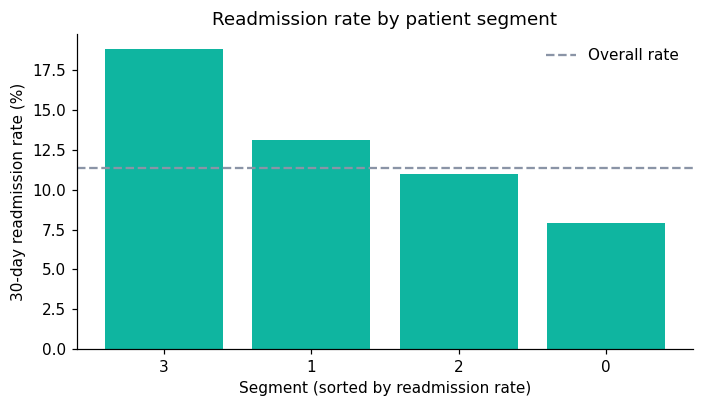

In [14]:
K = 4   # change after looking at the silhouette scores above
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
elig["segment"] = km.labels_

profile = elig.groupby("segment").agg(
    encounters=("readmitted_30d", "size"),
    readmit_rate=("readmitted_30d", "mean"),
    age=("age_mid", "mean"),
    stay_days=("time_in_hospital", "mean"),
    medications=("num_medications", "mean"),
    prior_inpatient=("number_inpatient", "mean"),
    prior_emergency=("number_emergency", "mean"),
    prior_outpatient=("number_outpatient", "mean"),
).sort_values("readmit_rate", ascending=False)
profile["share"] = profile["encounters"] / profile["encounters"].sum()
display(profile.style.format({"encounters": "{:,}", "readmit_rate": "{:.1%}", "share": "{:.1%}",
                              "age": "{:.0f}", "stay_days": "{:.1f}", "medications": "{:.1f}",
                              "prior_inpatient": "{:.2f}", "prior_emergency": "{:.2f}",
                              "prior_outpatient": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
order = profile.index.astype(str)
ax.bar(order, profile["readmit_rate"] * 100, color=TEAL)
ax.axhline(elig["readmitted_30d"].mean() * 100, color=GREY, ls="--", label="Overall rate")
ax.set_xlabel("Segment (sorted by readmission rate)"); ax.set_ylabel("30-day readmission rate (%)")
ax.set_title("Readmission rate by patient segment"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/py_segments.png"); plt.show()

**Name your segments.** Look at the profile table and give each segment a short label based on its averages, for example "Frequent returners" (high prior inpatient visits), "Short, low-complexity stays" or "Older, medication-heavy patients". Write the names and one sentence on each below.

- Segment 0: ...
- Segment 1: ...
- Segment 2: ...
- Segment 3: ...

## 6. Summary

Fill these in from the outputs above before you publish.

- **Reproduced SQL findings:** overall readmission rate ___%, prior visits 0 → 5+ raises risk from ___% to ___%, ___% of patients cause half of readmissions.
- **Model on unseen patients:** best model ___ with ROC-AUC ___ (baseline using prior visits only: ___). The top 10% highest-risk encounters were readmitted at ___% (lift ___x).
- **Top factors:** ___, ___, ___ (associations, not causes).
- **Segments:** the highest-risk segment is ___ (___% of encounters) with a ___% readmission rate.

**Limitations:** 1999–2008 data with no admission dates; descriptive findings only; the model is a ranking tool and the probabilities are not calibrated because the classes were re-weighted.

In [15]:
   !zip -r /kaggle/working/docs.zip /kaggle/working/docs

  adding: kaggle/working/docs/ (stored 0%)
  adding: kaggle/working/docs/py_prior_stays.png (deflated 13%)
  adding: kaggle/working/docs/py_segments.png (deflated 14%)
  adding: kaggle/working/docs/py_feature_importance.png (deflated 16%)
  adding: kaggle/working/docs/py_risk_deciles.png (deflated 14%)
  adding: kaggle/working/docs/py_discharge.png (deflated 15%)
  adding: kaggle/working/docs/py_pareto.png (deflated 8%)
